# Assignment 4: Reweighing Bias-Mitigation Algorithm Implementation

**Course:** Data Wrangling  
**Author:** Karla Hernandez Guerrero  
**Master’s programme:** Applied Data Science

This notebook implements and evaluates Reweighing using IBM’s
AI Fairness 360 (AIF360) library. It accompanies a review of
Kamiran and Calders’ (2012) “Data preprocessing techniques for
classification without discrimination,” which develops earlier
work by Calders, Kamiran, and Pechenizkiy (2009).

Reweighing assigns weights to training observations according
to their sensitive-group and outcome-label combinations.
It changes their influence during training without modifying
their feature values or labels.

The analysis evaluates the method on Adult Census, German
Credit, and COMPAS using logistic regression. The selected
sensitive attributes are sex for Adult and German Credit,
and race for COMPAS.

The experiment evaluates the method in a new setting rather
than reproducing the original paper’s numerical results.

## Running the notebook

1. Open this notebook in Google Colab.
2. Run the installation cell.
3. Upload `adult.csv` and `german.data` to the active session.
4. Run the remaining cells in order.

The notebook downloads `compas-scores-two-years.csv` automatically.
The earlier `assessment-only compas.csv` is not used.

## Evaluation conventions

- Favorable outcomes are encoded as `1`.
- The designated unprivileged/privileged groups are Female/Male
  for Adult and German Credit, and African-American/Caucasian
  for COMPAS.
- The `70/30 split` is stratified jointly by group and outcome,
  using `random seed 42`.
- Feature transformations are fitted only on training data.
- The selected sensitive attribute is excluded from classifier
  inputs but used for weighting and fairness evaluation.
- Original-label metrics are calculated before mitigation and
  classifier training.
- Baseline and Reweighing predictions are evaluated on identical
  held-out test observations.
- DP_Diff uses unprivileged minus privileged favorable-outcome rates.
- Consistency uses five nearest neighbors in the transformed
  predictor space, excluding the observation itself and the
  selected sensitive attribute.



# Step 1: Install libraries and dependencies

In [1]:
%pip install -q aif360==0.6.1

In [2]:
# Set up dependencies and libraries for the entire notebook

# For basic data manipulation
import numpy as np
import pandas as pd

# For data visualization
import matplotlib.pyplot as plt

# For the entire algorithmic-bias mitigation pipeline
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.neighbors import NearestNeighbors

# For algorithmic fairness evaluation
from aif360.datasets import BinaryLabelDataset
from aif360.algorithms.preprocessing import Reweighing

# For setting path dependencies
from pathlib import Path

# For importing files from google colab
from google.colab import files

# For reproducibility purposes
SEED = 42 # use same seed
TEST_SIZE = 0.30 # know test size
RESULTS_DIR = Path("/content/results") # set path for results directory
RESULTS_DIR.mkdir(exist_ok=True)

pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


# Step 2: Load, clean, and validate the datasets

Here, this specific cell standardizes capitalization, defines favorable outcomes consistently, and selects appropriate COMPAS predictors.

In [3]:
# ---------- Helper functions ----------

def find_file(filename):
    for folder in [Path("/content"), Path("/"), Path.cwd()]:
        path = folder / filename
        if path.is_file():
            return path

    raise FileNotFoundError(
        f"Please upload {filename} using Colab's Files panel."
    )


def clean_text(df):
    df = df.copy()

    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(r"[^a-z0-9]+", "_", regex=True)
        .str.strip("_")
    )

    if df.columns.duplicated().any():
        raise ValueError("Column names became duplicated after cleaning.")

    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = (
            df[col]
            .astype("string")
            .str.strip()
            .str.lower()
            .replace({"?": pd.NA, "": pd.NA, "n/a": pd.NA})
        )

    return df


def check_columns(df, columns):
    missing = set(columns) - set(df.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")


def map_checked(series, mapping, name):
    unexpected = series.notna() & ~series.isin(mapping)

    if unexpected.any():
        raise ValueError(
            f"Unexpected values in {name}: "
            f"{series[unexpected].unique().tolist()}"
        )

    return series.map(mapping)


# ---------- Adult ----------

adult_raw = clean_text(pd.read_csv(find_file("adult.csv")))

adult_features = [
    "age", "workclass", "education", "education_num",
    "marital_status", "occupation", "relationship", "race",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country"
]

check_columns(adult_raw, adult_features + ["income", "sex"])

adult = adult_raw[adult_features + ["income", "sex"]].copy()

income = adult.pop("income").astype("string").str.rstrip(".")

adult["label"] = map_checked(
    income,
    {"<=50k": 0, ">50k": 1, "0": 0, "1": 1},
    "income"
)

adult["protected"] = map_checked(
    adult.pop("sex"),
    {"female": 0, "male": 1},
    "Adult sex"
)

for col in [
    "age", "education_num", "capital_gain",
    "capital_loss", "hours_per_week"
]:
    adult[col] = pd.to_numeric(adult[col], errors="raise")

adult = adult.dropna().reset_index(drop=True)


# ---------- German Credit ----------

german_columns = [
    "status", "duration", "credit_history", "purpose", "amount",
    "savings", "employment_duration", "installment_rate",
    "personal_status_sex", "other_debtors", "present_residence",
    "property", "age", "other_installment_plans", "housing",
    "number_credits", "job", "people_liable", "telephone",
    "foreign_worker", "credit_risk"
]

german_raw = clean_text(
    pd.read_csv(
        find_file("german.data"),
        sep=r"\s+",
        names=german_columns,
        header=None
    )
)

german = german_raw.copy()

german["protected"] = map_checked(
    german.pop("personal_status_sex"),
    {
        "a91": 1,
        "a92": 0,
        "a93": 1,
        "a94": 1,
        "a95": 0
    },
    "German personal_status_sex"
)

german["label"] = map_checked(
    pd.to_numeric(german.pop("credit_risk"), errors="raise"),
    {1: 1, 2: 0},
    "credit_risk"
)

german = german.dropna().reset_index(drop=True)


# ---------- COMPAS ----------

# Download the outcome dataset, not the assessment-only dataset.
compas_url = (
    "https://raw.githubusercontent.com/propublica/"
    "compas-analysis/master/compas-scores-two-years.csv"
)

compas_path = Path("/content/compas-scores-two-years.csv")

if compas_path.exists():
    compas_raw = clean_text(pd.read_csv(compas_path))
else:
    downloaded = pd.read_csv(compas_url)
    downloaded.to_csv(compas_path, index=False)
    compas_raw = clean_text(downloaded)

compas_features = [
    "age", "sex", "juv_fel_count", "juv_misd_count",
    "juv_other_count", "priors_count", "c_charge_degree"
]

check_columns(
    compas_raw,
    compas_features + [
        "race", "two_year_recid", "days_b_screening_arrest",
        "is_recid", "score_text"
    ]
)

days = pd.to_numeric(
    compas_raw["days_b_screening_arrest"], errors="raise"
)

recid_flag = pd.to_numeric(
    compas_raw["is_recid"], errors="raise"
)

# Screening filters and the selected two-group comparison.
keep = (
    days.between(-30, 30)
    & recid_flag.notna()
    & recid_flag.ne(-1)
    & compas_raw["c_charge_degree"].ne("o")
    & compas_raw["score_text"].notna()
    & compas_raw["race"].isin(["caucasian", "african-american"])
)

compas = compas_raw.loc[
    keep,
    compas_features + ["race", "two_year_recid"]
].copy()

compas["protected"] = map_checked(
    compas.pop("race"),
    {"african-american": 0, "caucasian": 1},
    "COMPAS race"
)

# Favorable outcome = no recorded recidivism within two years.
compas["label"] = map_checked(
    pd.to_numeric(compas.pop("two_year_recid"), errors="raise"),
    {0: 1, 1: 0},
    "two_year_recid"
)

for col in [
    "age", "juv_fel_count", "juv_misd_count",
    "juv_other_count", "priors_count"
]:
    compas[col] = pd.to_numeric(compas[col], errors="raise")

compas = compas.dropna().reset_index(drop=True)


# ---------- Validate all three datasets ----------

DATASETS = {
    "Adult": adult,
    "German Credit": german,
    "COMPAS": compas
}

audit = []

for name, df in DATASETS.items():
    df["label"] = df["label"].astype(int)
    df["protected"] = df["protected"].astype(int)

    assert not df.isna().any().any(), f"{name}: missing values remain."
    assert set(df["label"].unique()) == {0, 1}
    assert set(df["protected"].unique()) == {0, 1}

    print(f"\n{name}: {len(df):,} cleaned observations")

    display(
        pd.crosstab(
            df["protected"],
            df["label"],
            rownames=["Protected: 0=unprivileged, 1=privileged"],
            colnames=["Label: 0=unfavorable, 1=favorable"]
        )
    )

    audit.append({
        "Dataset": name,
        "Cleaned observations": len(df),
        "Favorable outcome rate": df["label"].mean()
    })

pd.DataFrame(audit).to_csv(
    RESULTS_DIR / "data_audit.csv",
    index=False
)


Adult: 30,162 cleaned observations


"Label: 0=unfavorable, 1=favorable",0,1
"Protected: 0=unprivileged, 1=privileged",,
0,8670,1112
1,13984,6396



German Credit: 1,000 cleaned observations


"Label: 0=unfavorable, 1=favorable",0,1
"Protected: 0=unprivileged, 1=privileged",,
0,109,201
1,191,499



COMPAS: 5,278 cleaned observations


"Label: 0=unfavorable, 1=favorable",0,1
"Protected: 0=unprivileged, 1=privileged",,
0,1661,1514
1,822,1281


# Step 3: Train, evaluate, and save results

This third step produces four rows per dataset:

* Original labels across all cleaned observations: the assignment’s required starting metrics.

* Original labels in the test set: an additional reference.

* Predictions from an unweighted baseline.

* Predictions after Reweighing.

At the end of this code chunck, you can compare the last two rows to assess the effect of mitigation on the same test observations...

In [4]:
# ---------- Fairness metrics ----------

def neighbor_indices(X, k=5):
    """
    Find neighbors using model features, excluding the protected attribute.
    Exclude each observation itself from its neighbor list.
    """
    k = min(k, len(X) - 1)

    if k < 1:
        raise ValueError(
            "Consistency requires at least two observations."
        )

    search = NearestNeighbors(
        n_neighbors=k + 1,
        algorithm="brute",
        n_jobs=-1
    ).fit(X)

    neighbors = []

    # Process observations in batches to limit memory use.
    for start in range(0, len(X), 512):
        batch = X[start:start + 512]
        indices = search.kneighbors(
            batch,
            return_distance=False
        )

        for offset, row in enumerate(indices):
            own_index = start + offset
            neighbors.append(row[row != own_index][:k])

    return np.asarray(neighbors)


def fairness_metrics(labels, protected, neighbors):
    labels = np.asarray(labels, dtype=float)
    protected = np.asarray(protected)

    unprivileged_rate = labels[protected == 0].mean()
    privileged_rate = labels[protected == 1].mean()

    # Signed convention: unprivileged minus privileged.
    dp_diff = unprivileged_rate - privileged_rate

    dir_value = (
        unprivileged_rate / privileged_rate
        if privileged_rate > 0
        else np.nan
    )

    consistency = 1 - np.mean(
        np.abs(labels - labels[neighbors].mean(axis=1))
    )

    return {
        "DP_Diff": float(dp_diff),
        "DIR": float(dir_value),
        "Consistency": float(consistency)
    }


# ---------- One complete experiment ----------

def run_dataset(name, df):
    X = df.drop(columns=["label", "protected"])
    y = df["label"].to_numpy()
    protected = df["protected"].to_numpy()

    # Preserve group-label combinations in the split.
    strata = (
        df["protected"].astype(str)
        + "_"
        + df["label"].astype(str)
    )

    if strata.value_counts().min() < 2:
        raise ValueError(
            f"{name}: insufficient observations "
            "in a group-label combination."
        )

    train_idx, test_idx = train_test_split(
        np.arange(len(df)),
        test_size=TEST_SIZE,
        random_state=SEED,
        stratify=strata
    )

    categorical = X.select_dtypes(
        include=["object", "string", "category"]
    ).columns.tolist()

    numerical = [
        col for col in X.columns
        if col not in categorical
    ]

    # Fit feature transformations only on training observations.
    preprocessing = ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                numerical
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ),
                categorical
            )
        ],
        sparse_threshold=0
    )

    X_train = preprocessing.fit_transform(
        X.iloc[train_idx]
    )
    X_test = preprocessing.transform(
        X.iloc[test_idx]
    )
    X_all = preprocessing.transform(X)

    y_train = y[train_idx]
    y_test = y[test_idx]
    protected_test = protected[test_idx]

    # Reuse the same test-neighbor graph for all test comparisons.
    test_neighbors = neighbor_indices(X_test)
    all_neighbors = neighbor_indices(X_all)

    # Calculate original-label metrics BEFORE mitigation or training.
    rows = [
        {
            "Dataset": name,
            "Stage": "Original labels: full dataset",
            "N": len(df),
            **fairness_metrics(
                y,
                protected,
                all_neighbors
            ),
            "Accuracy": np.nan,
            "Balanced accuracy": np.nan
        },
        {
            "Dataset": name,
            "Stage": "Original labels: test set",
            "N": len(test_idx),
            **fairness_metrics(
                y_test,
                protected_test,
                test_neighbors
            ),
            "Accuracy": np.nan,
            "Balanced accuracy": np.nan
        }
    ]

    # Only group and label are needed to estimate Reweighing weights.
    training_groups = pd.DataFrame({
        "protected": protected[train_idx],
        "label": y_train
    })

    aif_training = BinaryLabelDataset(
        df=training_groups,
        label_names=["label"],
        protected_attribute_names=["protected"],
        favorable_label=1,
        unfavorable_label=0
    )

    reweighing = Reweighing(
        unprivileged_groups=[{"protected": 0}],
        privileged_groups=[{"protected": 1}]
    )

    # Apply Reweighing only to the training observations.
    weighted_training = reweighing.fit_transform(
        aif_training
    )
    weights = weighted_training.instance_weights

    assert np.isfinite(weights).all()
    assert (weights > 0).all()

    # Check that weighted training favorable-outcome rates match.
    weighted_rates = []

    for group in [0, 1]:
        mask = protected[train_idx] == group

        weighted_rates.append(
            np.average(
                y_train[mask],
                weights=weights[mask]
            )
        )

    np.testing.assert_allclose(
        weighted_rates[0],
        weighted_rates[1],
        atol=1e-10
    )

    print(
        f"{name}: weighted training favorable rates "
        f"= {weighted_rates[0]:.4f}, "
        f"{weighted_rates[1]:.4f}"
    )

    predictions = pd.DataFrame({
        "Row index": test_idx,
        "Protected": protected_test,
        "True label": y_test
    })

    # Train and evaluate both models on the same split.
    for stage, sample_weights in [
        ("Baseline predictions", None),
        ("Reweighing predictions", weights)
    ]:
        model = LogisticRegression(
            C=1.0,
            solver="lbfgs",
            max_iter=3000,
            random_state=SEED
        )

        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )

        predicted = model.predict(X_test)
        predictions[stage] = predicted

        rows.append({
            "Dataset": name,
            "Stage": stage,
            "N": len(test_idx),
            **fairness_metrics(
                predicted,
                protected_test,
                test_neighbors
            ),
            "Accuracy": accuracy_score(
                y_test,
                predicted
            ),
            "Balanced accuracy": balanced_accuracy_score(
                y_test,
                predicted
            )
        })

    filename = name.lower().replace(" ", "_")

    predictions.to_csv(
        RESULTS_DIR / f"{filename}_test_predictions.csv",
        index=False
    )

    return rows


# ---------- Run all datasets ----------

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

all_results = []

for dataset_name, dataset in DATASETS.items():
    print(f"\nRunning {dataset_name}...")

    all_results.extend(
        run_dataset(dataset_name, dataset)
    )

results_df = pd.DataFrame(all_results)

print("\nFinal results:")
display(results_df.round(4))

results_df.to_csv(
    RESULTS_DIR / "fairness_results.csv",
    index=False
)

print("\nResults saved in Colab's results folder.")


Running Adult...
Adult: weighted training favorable rates = 0.2489, 0.2489

Running German Credit...
German Credit: weighted training favorable rates = 0.7000, 0.7000

Running COMPAS...
COMPAS: weighted training favorable rates = 0.5298, 0.5298

Final results:


,Dataset,Stage,N,DP_Diff,DIR,Consistency,Accuracy,Balanced accuracy
0,Adult,Original labels: full dataset,30162,-0.2002,0.3622,0.7971,NaN,NaN
1,Adult,Original labels: test set,9049,-0.2001,0.3626,0.7919,NaN,NaN
2,Adult,Baseline predictions,9049,-0.1912,0.2916,0.9430,0.8453,0.7656
3,Adult,Reweighing predictions,9049,-0.0992,0.5656,0.9409,0.8424,0.7539
4,German Credit,Original labels: full dataset,1000,-0.0748,0.8966,0.6736,NaN,NaN
5,German Credit,Original labels: test set,300,-0.0795,0.8903,0.6433,NaN,NaN
6,German Credit,Baseline predictions,300,-0.0069,0.9908,0.7760,0.7533,0.6841
7,German Credit,Reweighing predictions,300,-0.0020,0.9973,0.7680,0.7500,0.6817
8,COMPAS,Original labels: full dataset,5278,-0.1323,0.7828,0.5905,NaN,NaN
9,COMPAS,Original labels: test set,1584,-0.1322,0.7828,0.5600,NaN,NaN



Results saved in Colab's results folder.


# Step 4: Format and visualize results in a comparison table

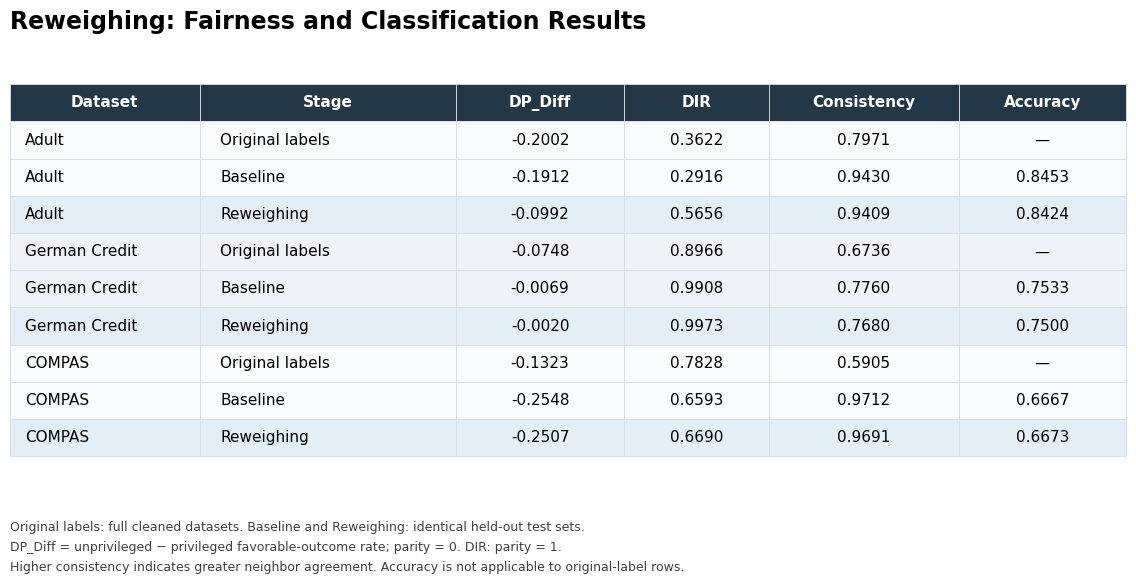

Image saved: /content/results/reweighing_results_table.png
CSV saved: /content/results/reweighing_results_table.csv


In [5]:
# Use the results already calculated in your notebook.
if "results_df" not in globals():
    raise NameError(
        "Run the training and evaluation cell first to create results_df."
    )

output_dir = Path("/content/results")
output_dir.mkdir(parents=True, exist_ok=True)

# Select the rows and columns needed for the report.
stages = [
    "Original labels: full dataset",
    "Baseline predictions",
    "Reweighing predictions"
]

columns = [
    "Dataset", "Stage", "DP_Diff", "DIR",
    "Consistency", "Accuracy"
]

report_table = results_df.loc[
    results_df["Stage"].isin(stages), columns
].copy()

# Keep datasets and stages in a consistent order.
dataset_order = ["Adult", "German Credit", "COMPAS"]

report_table["Dataset"] = pd.Categorical(
    report_table["Dataset"],
    categories=dataset_order,
    ordered=True
)

report_table["Stage"] = pd.Categorical(
    report_table["Stage"],
    categories=stages,
    ordered=True
)

report_table = (
    report_table.sort_values(["Dataset", "Stage"])
    .reset_index(drop=True)
)

# Save numeric values before formatting for display.
csv_path = output_dir / "reweighing_results_table.csv"
report_table.to_csv(csv_path, index=False)

# Create readable display labels.
display_table = report_table.copy()

display_table["Stage"] = (
    display_table["Stage"]
    .astype("object")
    .replace({
        "Original labels: full dataset": "Original labels",
        "Baseline predictions": "Baseline",
        "Reweighing predictions": "Reweighing"
    })
)

metric_columns = ["DP_Diff", "DIR", "Consistency", "Accuracy"]

for column in metric_columns:
    display_table[column] = display_table[column].apply(
        lambda value: "—" if pd.isna(value) else f"{value:.4f}"
    )

# Draw the table.
fig, ax = plt.subplots(figsize=(12, 6.2))
fig.patch.set_facecolor("white")
ax.axis("off")

fig.suptitle(
    "Reweighing: Fairness and Classification Results",
    fontsize=17,
    fontweight="bold",
    x=0.05,
    ha="left",
    y=0.97
)

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=[0.17, 0.23, 0.15, 0.13, 0.17, 0.15],
    bbox=[0, 0, 1, 1]
)

table.auto_set_font_size(False)
table.set_fontsize(11)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#D8DEE6")
    cell.set_linewidth(0.6)

    if row == 0:
        cell.set_facecolor("#243746")
        cell.set_text_props(color="white", weight="bold")
        continue

    dataset = str(report_table.iloc[row - 1]["Dataset"])
    stage = str(report_table.iloc[row - 1]["Stage"])

    # Alternate shading by dataset.
    if dataset == "German Credit":
        cell.set_facecolor("#F0F3F6")
    else:
        cell.set_facecolor("#FAFBFC")

    # Highlight mitigated rows.
    if stage == "Reweighing predictions":
        cell.set_facecolor("#E4EEF7")

    if col in [0, 1]:
        cell.set_text_props(ha="left")
        cell.PAD = 0.08

# Reserve separate areas for the title, table, and notes.
fig.subplots_adjust(
    left=0.05,
    right=0.98,
    top=0.85,
    bottom=0.25
)

# Use one text block to prevent overlapping notes.
notes = (
    "Original labels: full cleaned datasets. "
    "Baseline and Reweighing: identical held-out test sets.\n"
    "DP_Diff = unprivileged − privileged favorable-outcome rate; "
    "parity = 0. DIR: parity = 1.\n"
    "Higher consistency indicates greater neighbor agreement. "
    "Accuracy is not applicable to original-label rows."
)

fig.text(
    0.05,
    0.06,
    notes,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#404040",
    linespacing=1.7
)

# Save the updated image.
png_path = output_dir / "reweighing_results_table.png"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.2,
    facecolor="white"
)

plt.show()

print(f"Image saved: {png_path}")
print(f"CSV saved: {csv_path}")

# Step 5: Save and download results from Google Colab

In [6]:
# Download the table from Google Colab
files.download("/content/results/reweighing_results_table.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>